ابتدا فایل را میخوانیم

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("online+retail/Online Retail.xlsx")

تعداد سطر و ستون دیتاست رو مشاهده می کنیم

In [12]:
df.shape

(541909, 8)

اسم ستون هارو مشاهده می کنیم ببینیم چی داریم

In [13]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

۵ سطر اول هم مشاهده میکنیم کلا ببینیم چی به چیه

In [14]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


InvoiceNo — شماره فاکتور


StockCode — کد محصول


Description — توضیحات محصول


Quantity — تعداد کالا


InvoiceDate — تاریخ و ساعت فاکتور


UnitPrice — قیمت هر واحد


CustomerID — شناسه‌ی مشتری


Country — کشور مشتری



In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


از df.info() استفاده کردیم تا یک دید کلی از ساختار دیتاست بگیریم؛ یعنی تعداد ردیف‌ها و ستون‌ها، نوع داده‌های هر ستون، تعداد مقادیر غیرگمشده و میزان حافظه مصرفی را بررسی کنیم تا مشکلات احتمالی داده‌ها را قبل از تحلیل شناسایی کنیم.

حالا امار توصیفی داده هامون رو بررسی می کنیم

In [16]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


 مقدارهای بسیار بزرگ یا منفی در Quantity


 قیمت‌های صفر یا منفی و قیمت‌های بسیار بزرگ در UnitPrice
 

 ردیف‌های بدون CustomerID که ممکن است برای RFM قابل استفاده نباشند

In [17]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

print("Quantity < 0:", (df["Quantity"] < 0).sum())

print("UnitPrice < 0:", (df["UnitPrice"] < 0).sum())

Quantity <= 0: 10624
UnitPrice <= 0: 2517
Quantity < 0: 10624
UnitPrice < 0: 2


تعداد منفی (Quantity)

در این دیتاست، تعداد منفی معمولاً نشان‌دهنده‌ی برگشت کالا یا لغو بخشی از خرید است. مثلاً مشتری کالایی رو خریده و بعد پس داده.

قیمت صفر (UnitPrice)

ممکنه محصول رایگان، نمونه تبلیغاتی یا یک ثبت خاص باشه. باید ردیف‌ها رو بررسی کنیم تا دلیلش مشخص بشه.

قیمت منفی (UnitPrice)

فقط دو مورد داریم؛ این‌ها غیرعادی هستن و باید جزئیاتشون رو ببینیم. بدون بررسی نباید فرض کنیم خطای ثبت هستن.

In [18]:
display(df[df["Quantity"] < 0][["InvoiceNo", "StockCode", "Description","Quantity", "UnitPrice", "CustomerID"]].head(10))


display(df[df["UnitPrice"] == 0][["InvoiceNo", "StockCode", "Description","Quantity", "UnitPrice", "CustomerID"]].head(10))


display(df[df["UnitPrice"] < 0][["InvoiceNo", "StockCode", "Description","Quantity", "UnitPrice", "CustomerID"]])

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
141,C536379,D,Discount,-1,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,17897.0


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
622,536414,22139,NaN,56,0.0,NaN
1970,536545,21134,NaN,1,0.0,NaN
1971,536546,22145,NaN,1,0.0,NaN
1972,536547,37509,NaN,1,0.0,NaN
1987,536549,85226A,NaN,1,0.0,NaN
1988,536550,85044,NaN,1,0.0,NaN
2024,536552,20950,NaN,1,0.0,NaN
2025,536553,37461,NaN,3,0.0,NaN
2026,536554,84670,NaN,23,0.0,NaN
2406,536589,21777,NaN,-10,0.0,NaN


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN


فاکتورهایی که شماره‌شان با C شروع می‌شود، معمولاً فاکتورهای لغوشده هستند. این نمونه‌ها با این الگو سازگارند.

تحلیل قیمت‌های صفر (UnitPrice == 0)
در نمونه‌ها می‌بینیم که:
Description خالی است.
CustomerID خالی است.
قیمت کالا صفر است.
بعضی ردیف‌ها تعداد مثبت و بعضی تعداد منفی دارند.
مثلاً در فاکتور 536414 تعداد ۵۶ واحد ثبت شده، اما قیمت صفر و شناسه مشتری نامشخص است.

تحلیل قیمت‌های منفی (UnitPrice < 0)
این دو ردیف با فروش معمولی محصول تفاوت دارند. توضیح Adjust bad debt به معنی اصلاح یا تعدیل بدهی سوخت‌شده است؛ یعنی احتمالاً یک ثبت حسابداری برای تعدیل بدهی، نه فروش عادی کالا.

همچنین کد محصول B و شماره فاکتورهایی که با A شروع می‌شوند، با الگوی معمول فروش کالا متفاوت‌اند.

In [19]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


۲ ستون مقدار گمشده دارن

Description با ۱۴۵۴ مقدار

CustomerID با ۱۳۵۰۸۰ مقدار

In [20]:
selected_columns = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country"
]

selected_data = df[selected_columns].copy()

In [21]:
missing_percentage = selected_data.isnull().mean() * 100
print(missing_percentage)

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


یک کپی از تمام ستون ها گرفتیم و درصد مقادیر گمشده رو بررسی کردیم


تقریباً یک‌ چهارم شناسه‌های مشتری خالی هستند 

رکورد های تکراری رو بررسی می کنیم

In [22]:
df.duplicated().sum()

np.int64(5268)

In [23]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [24]:
print("Unique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique products:", df["StockCode"].nunique())

Unique customers: 4372
Unique invoices: 25900
Unique products: 4070


بررسی بازه زمانی داده‌ها


قدیمی‌ترین و جدیدترین تاریخ ثبت‌شده در دیتاست را مشخص می‌کنم

In [25]:
print("Start date:", df["InvoiceDate"].min())
print("End date:", df["InvoiceDate"].max())

Start date: 2010-12-01 08:26:00
End date: 2011-12-09 12:50:00


In [26]:
print(df["Country"].value_counts().head(10))

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64


۱۰ کشور دارای بیشترین تعداد ردیف در دیتاست رو نمایش می‌ده

انگلیس رتبه اول رو داره

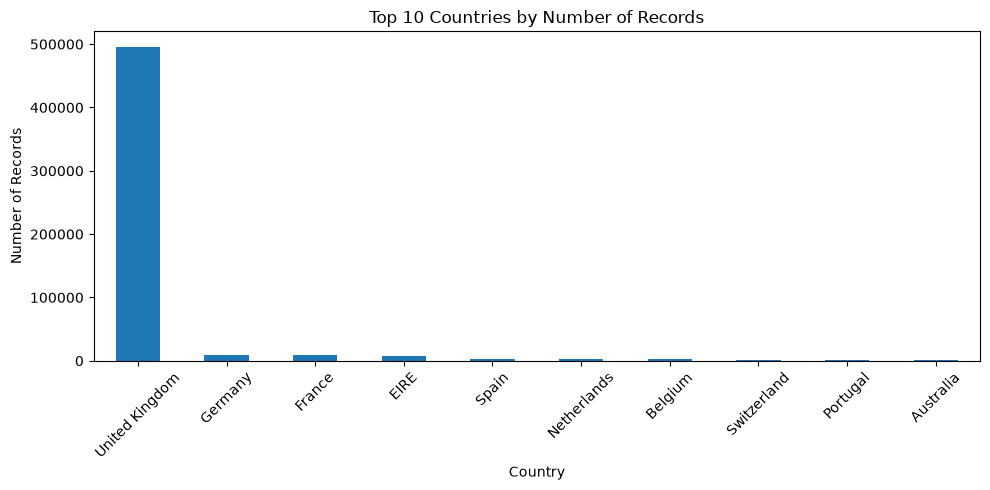

In [27]:
import matplotlib.pyplot as plt

country_counts = df["Country"].value_counts().head(10)

country_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Number of Records")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

این دیتاست از نظر تعداد رکوردها به‌شدت روی بازار بریتانیا متمرکزه؛ بنابراین هنگام تحلیل فروش کشورها باید تفاوت اندازه بازارها رو در نظر بگیریم

این نمودار تعداد ردیف‌ها رو مقایسه می‌کنه، نه تعداد مشتریان، تعداد سفارش‌ها یا مبلغ فروش

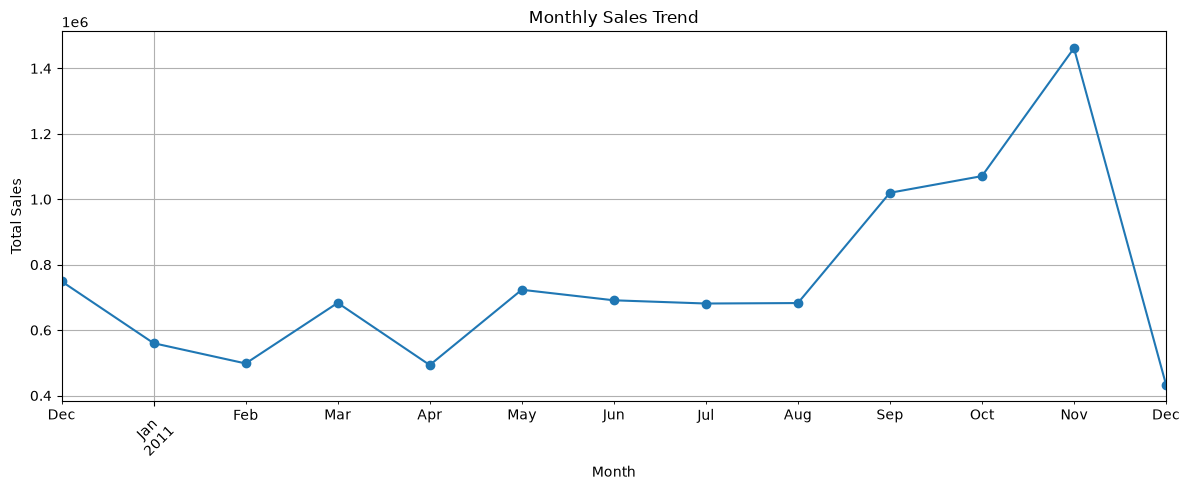

In [28]:
sales_data = df.assign(TotalPrice=df["Quantity"] * df["UnitPrice"])

monthly_sales = sales_data.groupby(
    sales_data["InvoiceDate"].dt.to_period("M")
)["TotalPrice"].sum()

monthly_sales.plot(kind="line", figsize=(12, 5), marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


دسامبر ۲۰۱۰: فروش حدود ۷۵۰ هزار واحد پولی بوده و نسبتاً بالاست.



ژانویه و فوریه ۲۰۱۱: فروش کاهش پیدا کرده و در فوریه به حدود ۵۰۰ هزار رسیده.



مارس: فروش دوباره افزایش پیدا کرده، اما در آوریل افت محسوسی داره.



مه تا اوت: فروش نسبتاً ثابت مونده و در محدوده ۶۸۰ تا ۷۲۵ هزار قرار گرفته.



سپتامبر و اکتبر: فروش رشد چشمگیری داشته و از حدود یک میلیون عبور کرده.



نوامبر: بیشترین فروش ثبت‌شده، حدود ۱.۴۶ میلیون بوده.



دسامبر ۲۰۱۱: فروش به حدود ۴۳۰ هزار کاهش پیدا کرده؛ اما چون داده‌ها فقط تا ۹ دسامبر ثبت شدن، این ماه ناقصه و مقایسه مستقیمش با ماه‌های کامل درست نیست

1. فروش از سپتامبر تا نوامبر روند افزایشی قابل‌توجهی داشته است.

2. نوامبر بیشترین مبلغ فروش ثبت‌شده را دارد؛ بررسی عوامل این رشد می‌تواند موضوع تحلیل بعدی باشد.

3. افت فروش در فوریه و آوریل نشان می‌دهد روند فروش در طول سال کاملاً یکنواخت نیست.

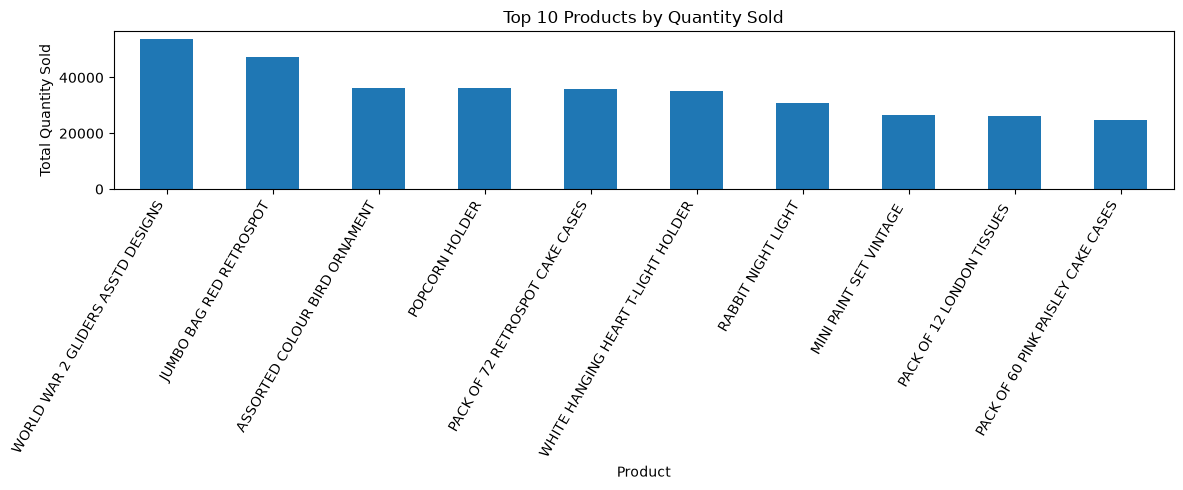

In [29]:
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.plot(kind="bar", figsize=(12, 5))

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Product")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

۱۰ محصولی رو نشون می‌ده که بیشترین تعداد فروش ثبت‌شده رو دارن

محصول اول: WORLD WAR 2 GLIDERS ASSTD DESIGNS با حدود ۵۳ هزار عدد، بیشترین مجموع تعداد ثبت‌شده رو داره.



محصول دوم: JUMBO BAG RED RETROSPOT با حدود ۴۷ هزار عدد در رتبه دوم قرار گرفته.



محصولات بعدی: ASSORTED COLOUR BIRD ORNAMENT و POPCORN HOLDER هر کدوم حدود ۳۶ هزار عدد فروش ثبت‌شده دارن.



۱۰ محصول برتر: اختلاف تعداد بین محصول اول و محصولات انتهایی قابل‌توجهه؛ محصول اول تقریباً دو برابر بعضی محصولات انتهای فهرسته.

1. تقاضای ثبت‌شده برای محصولات مختلف یکسان نیست و بعضی محصولات تعداد فروش بیشتری دارن.

2. محصولات پرفروش می‌تونن برای تحلیل الگوی خرید مشتریان و پیشنهاد محصولات مرتبط مفید باشن.

3. چون در محاسبه از ستون Quantity خام استفاده کردیم، مقادیر منفی ناشی از مرجوعی یا لغو سفارش هم ممکنه روی رتبه‌بندی اثر گذاشته باشن؛ پس فعلاً این نتایج مقدماتی هستن.

این نمودار بر اساس تعداد کالاهاست، نه مبلغ درآمد؛ ممکنه محصولی تعداد فروش بیشتری داشته باشه، ولی درآمد کمتری نسبت به محصولی با قیمت بالاتر ایجاد کنه.

/tmp/ipykernel_4078/3682240808.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["UnitPrice"].dropna(), vert=False)


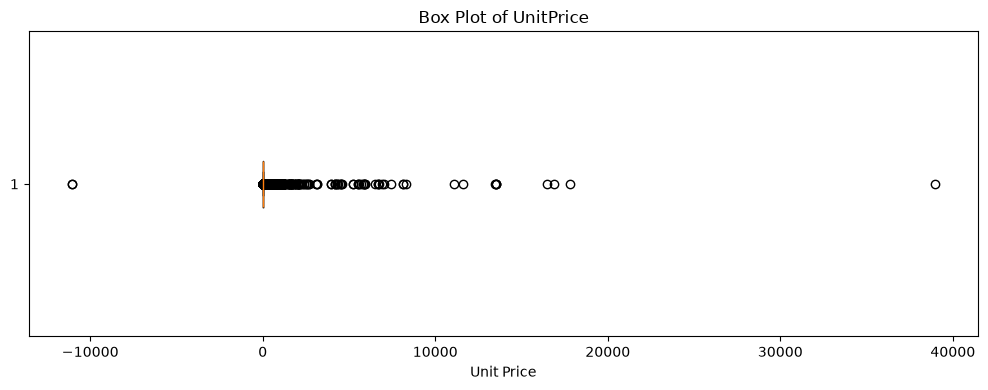

In [30]:
plt.figure(figsize=(10, 4))

plt.boxplot(df["UnitPrice"].dropna(), vert=False)

plt.title("Box Plot of UnitPrice")
plt.xlabel("Unit Price")

plt.tight_layout()
plt.show()

تجمع قیمت‌ها: بیشتر قیمت‌ها نزدیک صفر و در محدوده نسبتاً کوچکی قرار دارن؛ به همین دلیل جعبه نمودار خیلی فشرده دیده می‌شه.



مقادیر پرت مثبت: چند قیمت بسیار بزرگ، از چند هزار تا حدود ۳۹٬۰۰۰، دیده می‌شن.



مقدار پرت منفی: یک قیمت حدود ۱۱٬۰۰۰- وجود داره که با قیمت معمول محصول سازگار نیست و باید بررسی بشه.



چولگی به راست: وجود قیمت‌های مثبت بسیار بزرگ نشون می‌ده توزیع قیمت‌ها به‌شدت به سمت راست کشیده شده.

این نمودار نشون می‌ده ستون UnitPrice مقادیر غیرعادی داره

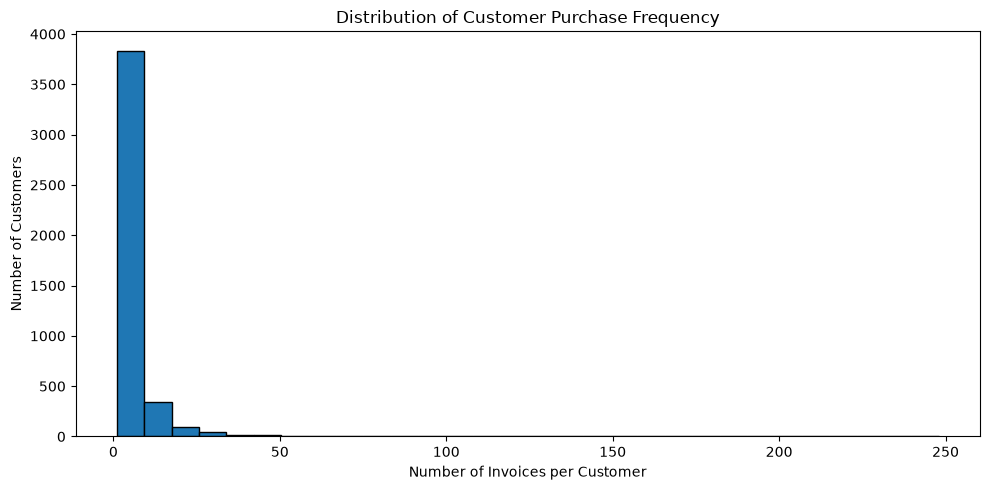

In [31]:
customer_frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()

plt.figure(figsize=(10, 5))

plt.hist(customer_frequency, bins=30, edgecolor="black")

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Number of Invoices per Customer")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

- بیشتر مشتری‌ها: کمتر از ۱۰ فاکتور دارن؛ یعنی تعداد خریدشون در مقایسه با مشتریان پرتکرار کمه.
- تعداد مشتری‌ها با افزایش خرید کم می‌شه: هرچه تعداد فاکتورهای مشتری بیشتر می‌شه، تعداد مشتری‌هایی که در اون محدوده قرار می‌گیرن کاهش پیدا می‌کنه.
- توزیع به‌شدت چوله به راست است: تعداد زیادی از مشتری‌ها خریدهای نسبتاً کمی دارن، ولی تعداد محدودی مشتری، فاکتورهای بسیار زیادی ثبت کردن.
- مقادیر دور از بقیه: وجود مشتریانی با بیش از ۵۰ و حتی تعداد بسیار بیشتری فاکتور، نشون می‌ده رفتار خرید مشتری‌ها یکسان نیست؛ البته این مقادیر لزوماً خطا یا داده پرت نامعتبر نیستن.
این نمودار نشون می‌ده مشتری‌ها از نظر تعداد خرید تفاوت قابل‌توجهی دارن؛ بنابراین Frequency می‌تونه برای شناسایی مشتریان پرتکرار و بخش‌بندی مشتری‌ها مفید باشه.

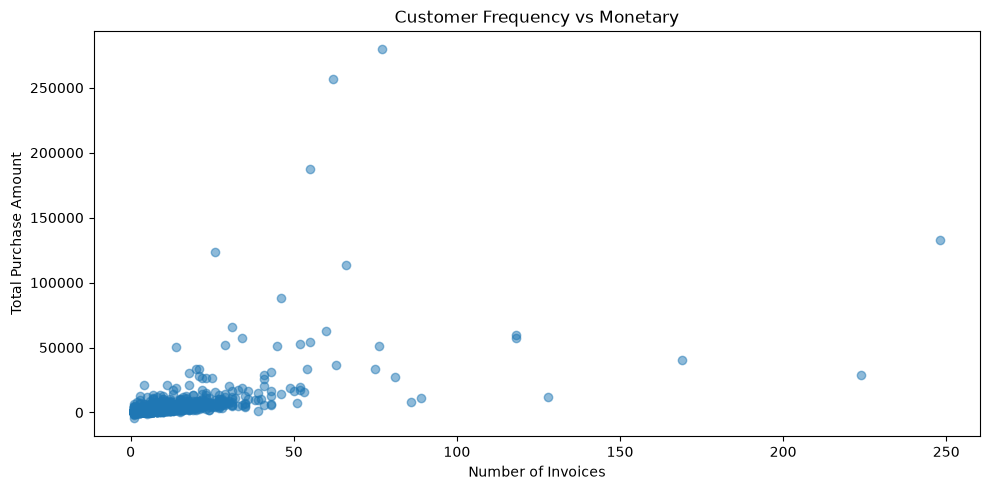

In [32]:
customer_data = df.assign(
    TotalPrice=df["Quantity"] * df["UnitPrice"]
).groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
)

plt.figure(figsize=(10, 5))

plt.scatter(
    customer_data["Frequency"],
    customer_data["Monetary"],
    alpha=0.5
)

plt.title("Customer Frequency vs Monetary")
plt.xlabel("Number of Invoices")
plt.ylabel("Total Purchase Amount")

plt.tight_layout()
plt.show()


تجمع اصلی مشتری‌ها: بیشتر نقاط نزدیک گوشه پایینِ سمت چپ قرار دارن؛ یعنی بیشتر مشتری‌ها هم تعداد فاکتور نسبتاً کمی دارن و هم مبلغ خریدشون در مقایسه با مشتریان بزرگ کمتره.



رابطه مثبت احتمالی: به‌طور کلی با افزایش تعداد فاکتورها، مبلغ خرید هم در بسیاری از موارد افزایش پیدا می‌کنه؛ اما این رابطه کاملاً منظم نیست.



مشتریان باارزش: چند مشتری با مبلغ خرید بسیار بالا دیده می‌شن؛ مثلاً بعضی‌ها با حدود ۶۰ تا ۸۰ فاکتور، مبلغ خرید بالایی دارن.



استثناهای مهم: یک مشتری با حدود ۲۵۰ فاکتور وجود داره که مبلغ خریدش از بعضی مشتریان با فاکتورهای کمتر، پایین‌تره. پس تعداد خرید به‌تنهایی معیار کافی برای ارزش مشتری نیست.



پراکندگی زیاد: مشتریانی با تعداد فاکتور مشابه، می‌تونن مبلغ خرید کاملاً متفاوتی داشته باشن.

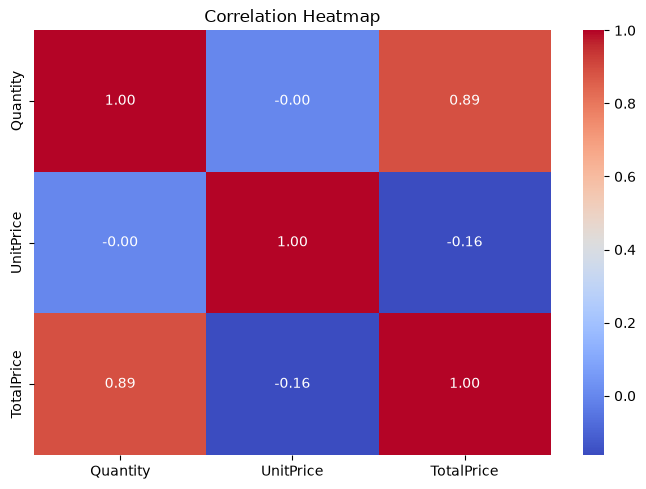

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = df[["Quantity", "UnitPrice"]].copy()

numeric_data["TotalPrice"] = (
    numeric_data["Quantity"] * numeric_data["UnitPrice"]
)

correlation = numeric_data.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

بررسی فاکتورهای لغوشده

In [34]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

print("Cancelled rows:", cancelled.sum())

print(
    "Cancelled invoices:",
    df.loc[cancelled, "InvoiceNo"].nunique()
)

print(
    "Percentage of rows:",
    round(cancelled.mean() * 100, 2),
    "%"
)

Cancelled rows: 9288
Cancelled invoices: 3836
Percentage of rows: 1.71 %


۹۲۸۸ ردیف: مربوط به فاکتورهایی هستن که شماره‌شون با C شروع می‌شه.



۳۸۳۶ فاکتور لغوشده: این تعداد فاکتور یکتا در دیتاست ثبت شده.



۱٫۷۱٪ از ردیف‌ها: مربوط به فاکتورهای لغوشده است.

In [35]:
missing_customers = df["CustomerID"].isnull().sum()

print("Missing CustomerID:", missing_customers)
print(
    "Percentage:",
    round(df["CustomerID"].isnull().mean() * 100, 2),
    "%"
)

Missing CustomerID: 135080
Percentage: 24.93 %


این کد تعداد و درصد ردیف‌هایی رو محاسبه می‌کنه که شناسه مشتری ندارن و در نتیجه نمی‌شه خریدهاشون رو مستقیماً به یک مشتری مشخص در تحلیل RFM نسبت داد

۱۳۵٬۰۸۰ ردیف شناسه مشتری ندارن.



این مقدار برابر با ۲۴٫۹۳٪ کل ردیف‌ها است؛ یعنی تقریباً یک‌چهارم دیتاست.

In [36]:
customer_frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()

print(customer_frequency.describe())

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64


میانگین حدود ۵ است، اما میانه فقط ۳ است. این اختلاف، همراه با حداکثر ۲۴۸ فاکتور، نشون می‌ده توزیع تعداد خریدها به‌شدت به سمت راست چوله است؛ یعنی تعداد کمی مشتری خریدهای بسیار زیادی دارن.

In [37]:
customer_monetary = (df.assign(TotalPrice=df["Quantity"] * df["UnitPrice"]).groupby("CustomerID")["TotalPrice"].sum())
print(customer_monetary.describe())

count      4372.000000
mean       1898.459701
std        8219.345141
min       -4287.630000
25%         293.362500
50%         648.075000
75%        1611.725000
max      279489.020000
Name: TotalPrice, dtype: float64


میانگین حدود ۱٬۸۹۸ است، اما میانه حدود ۶۴۸؛ یعنی تعداد محدودی مشتری با مبالغ بالا میانگین را افزایش داده‌اند.



مقدار منفی می‌تواند به‌دلیل مرجوعی‌ها، لغو سفارش‌ها یا اصلاحات مالی باشد؛ فعلاً نباید آن را خودکار حذف کنیم.



بیشترین مقدار بسیار بزرگ است. این مورد را باید بررسی کنیم، اما بزرگ بودن به‌تنهایی به معنی اشتباه بودن داده نیست.